In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [2]:
airbnb = pd.read_csv('listings.csv')

In [3]:
print("Dimensiones:", airbnb.shape)
airbnb.head()

Dimensiones: (7907, 16)


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,49091,COZICOMFORT LONG TERM STAY ROOM 2,266763,Francesca,North Region,Woodlands,1.44255,103.79580,Private room,83,180,1,2013-10-21,0.01,2,365
1,50646,Pleasant Room along Bukit Timah,227796,Sujatha,Central Region,Bukit Timah,1.33235,103.78521,Private room,81,90,18,2014-12-26,0.28,1,365
2,56334,COZICOMFORT,266763,Francesca,North Region,Woodlands,1.44246,103.79667,Private room,69,6,20,2015-10-01,0.20,2,365
3,71609,Ensuite Room (Room 1 & 2) near EXPO,367042,Belinda,East Region,Tampines,1.34541,103.95712,Private room,206,1,14,2019-08-11,0.15,9,353
4,71896,B&B Room 1 near Airport & EXPO,367042,Belinda,East Region,Tampines,1.34567,103.95963,Private room,94,1,22,2019-07-28,0.22,9,355


In [4]:
airbnb.info()

<class 'pandas.DataFrame'>
RangeIndex: 7907 entries, 0 to 7906
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              7907 non-null   int64  
 1   name                            7905 non-null   str    
 2   host_id                         7907 non-null   int64  
 3   host_name                       7907 non-null   str    
 4   neighbourhood_group             7907 non-null   str    
 5   neighbourhood                   7907 non-null   str    
 6   latitude                        7907 non-null   float64
 7   longitude                       7907 non-null   float64
 8   room_type                       7907 non-null   str    
 9   price                           7907 non-null   int64  
 10  minimum_nights                  7907 non-null   int64  
 11  number_of_reviews               7907 non-null   int64  
 12  last_review                     5149 non-null

In [5]:
faltantes = airbnb.isnull().sum()
porcentaje = (airbnb.isnull().sum() / len(airbnb)) * 100

resumen_faltantes = pd.DataFrame({
    'faltantes': faltantes,
    'porcentaje': porcentaje.round(2)
})
resumen_faltantes = resumen_faltantes[resumen_faltantes['faltantes'] > 0]
print(resumen_faltantes)

                   faltantes  porcentaje
name                       2        0.03
last_review             2758       34.88
reviews_per_month       2758       34.88


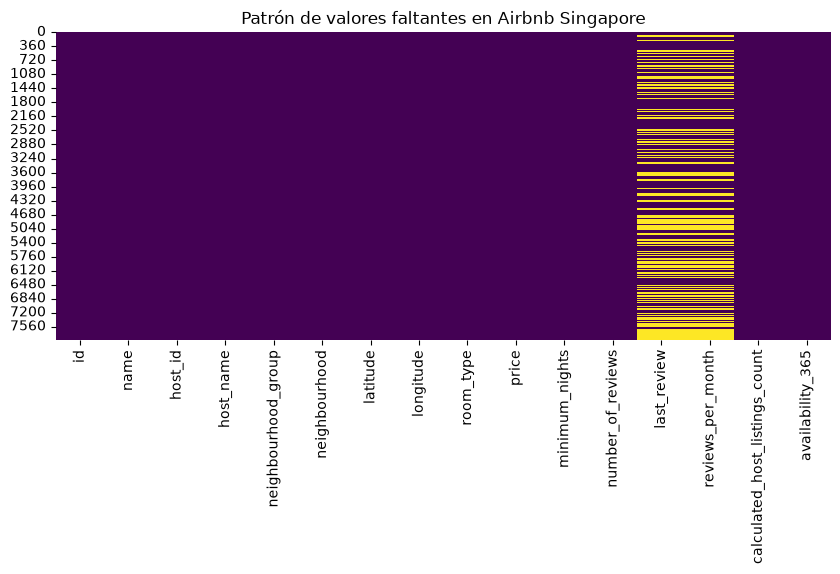

In [6]:
plt.figure(figsize=(10, 4))
sns.heatmap(airbnb.isnull(), cbar=False, cmap='viridis')
plt.title('Patrón de valores faltantes en Airbnb Singapore')
plt.show()

In [7]:
sin_resenas = airbnb[airbnb['number_of_reviews'] == 0]
print("Listings con 0 reseñas:", len(sin_resenas))
print("Faltantes en last_review:", airbnb['last_review'].isnull().sum())
print("Faltantes en reviews_per_month:", airbnb['reviews_per_month'].isnull().sum())

coincide = (airbnb['last_review'].isnull() == (airbnb['number_of_reviews'] == 0)).all()
print("¿Los faltantes coinciden con 0 reseñas?:", coincide)

Listings con 0 reseñas: 2758
Faltantes en last_review: 2758
Faltantes en reviews_per_month: 2758
¿Los faltantes coinciden con 0 reseñas?: True


In [8]:
airbnb_clean = airbnb.copy()

print("Filas antes:", airbnb_clean.shape[0])
airbnb_clean = airbnb_clean.dropna(subset=['name'])
print("Filas después:", airbnb_clean.shape[0])

Filas antes: 7907
Filas después: 7905


In [9]:
airbnb_clean['reviews_per_month'] = airbnb_clean['reviews_per_month'].fillna(0)
print("Faltantes restantes en reviews_per_month:", airbnb_clean['reviews_per_month'].isnull().sum())

Faltantes restantes en reviews_per_month: 0


In [10]:
airbnb_clean['last_review'] = pd.to_datetime(airbnb_clean['last_review'])
airbnb_clean['sin_reviews'] = airbnb_clean['last_review'].isnull().astype(int)
airbnb_clean['last_review'] = airbnb_clean['last_review'].fillna(pd.Timestamp('1900-01-01'))

print(airbnb_clean[['last_review', 'sin_reviews']].head())
print("Faltantes restantes en last_review:", (airbnb_clean['last_review'] == pd.Timestamp('1900-01-01')).sum())

  last_review  sin_reviews
0  2013-10-21            0
1  2014-12-26            0
2  2015-10-01            0
3  2019-08-11            0
4  2019-07-28            0
Faltantes restantes en last_review: 2757


In [11]:
columnas_numericas = ['price', 'minimum_nights', 'number_of_reviews', 
                       'reviews_per_month', 'availability_365']

print(airbnb[columnas_numericas].describe())

              price  minimum_nights  number_of_reviews  reviews_per_month  \
count   7907.000000     7907.000000        7907.000000        5149.000000   
mean     169.332996       17.510054          12.807386           1.043669   
std      340.187599       42.094616          29.707746           1.285851   
min        0.000000        1.000000           0.000000           0.010000   
25%       65.000000        1.000000           0.000000           0.180000   
50%      124.000000        3.000000           2.000000           0.550000   
75%      199.000000       10.000000          10.000000           1.370000   
max    10000.000000     1000.000000         323.000000          13.000000   

       availability_365  
count       7907.000000  
mean         208.726318  
std          146.120034  
min            0.000000  
25%           54.000000  
50%          260.000000  
75%          355.000000  
max          365.000000  


In [12]:
media = airbnb['reviews_per_month'].mean()
mediana = airbnb['reviews_per_month'].median()
print(f"Media de reviews_per_month (sin NaN): {media:.3f}")
print(f"Mediana de reviews_per_month (sin NaN): {mediana:.3f}")

Media de reviews_per_month (sin NaN): 1.044
Mediana de reviews_per_month (sin NaN): 0.550


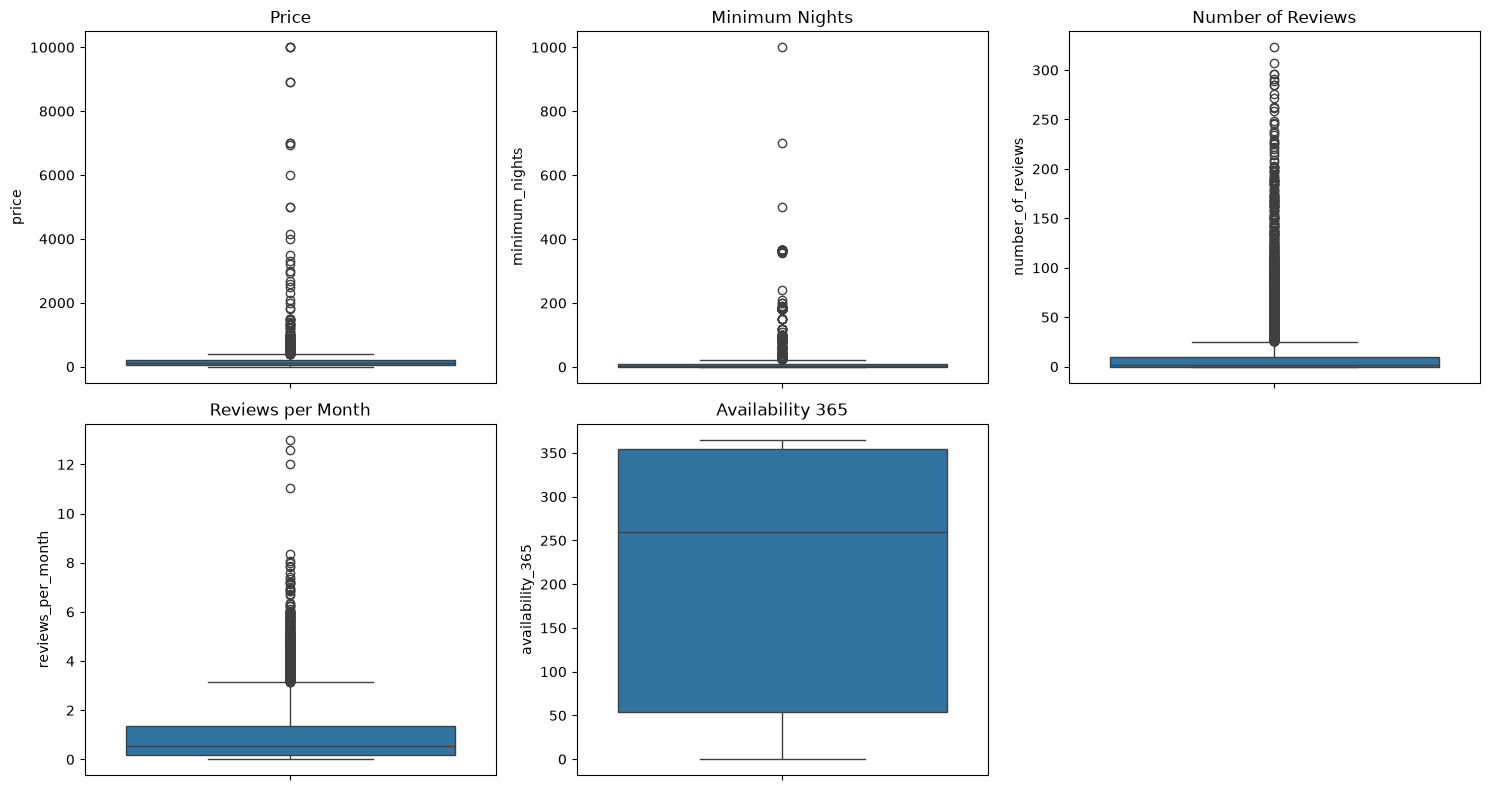

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

sns.boxplot(y=airbnb['price'], ax=axes[0,0])
axes[0,0].set_title('Price')

sns.boxplot(y=airbnb['minimum_nights'], ax=axes[0,1])
axes[0,1].set_title('Minimum Nights')

sns.boxplot(y=airbnb['number_of_reviews'], ax=axes[0,2])
axes[0,2].set_title('Number of Reviews')

sns.boxplot(y=airbnb['reviews_per_month'], ax=axes[1,0])
axes[1,0].set_title('Reviews per Month')

sns.boxplot(y=airbnb['availability_365'], ax=axes[1,1])
axes[1,1].set_title('Availability 365')

fig.delaxes(axes[1,2])  # celda vacía, no tenemos 6ta variable

plt.tight_layout()
plt.show()

In [14]:
np.random.seed(42)
airbnb_demo = airbnb.copy()
mask = np.random.choice(airbnb_demo.index, size=200, replace=False)
airbnb_demo.loc[mask, 'price'] = np.nan

print("Faltantes simulados en price:", airbnb_demo['price'].isnull().sum())

precio_prom = airbnb_demo['price'].mean()
imputado_prom = airbnb_demo['price'].fillna(precio_prom)

precio_mediana = airbnb_demo['price'].median()
imputado_mediana = airbnb_demo['price'].fillna(precio_mediana)

print(f"\nValor usado con promedio: {precio_prom:.2f}")
print(f"Valor usado con mediana: {precio_mediana:.2f}")
print(f"\nDiferencia entre ambos: {abs(precio_prom - precio_mediana):.2f}")

Faltantes simulados en price: 200

Valor usado con promedio: 169.75
Valor usado con mediana: 124.00

Diferencia entre ambos: 45.75


Room Type
room_type
Entire home/apt    4132
Private room       3381
Shared room         394
Name: count, dtype: int64

Neighbourhood Group
neighbourhood_group
Central Region       6309
West Region           540
East Region           508
North-East Region     346
North Region          204
Name: count, dtype: int64


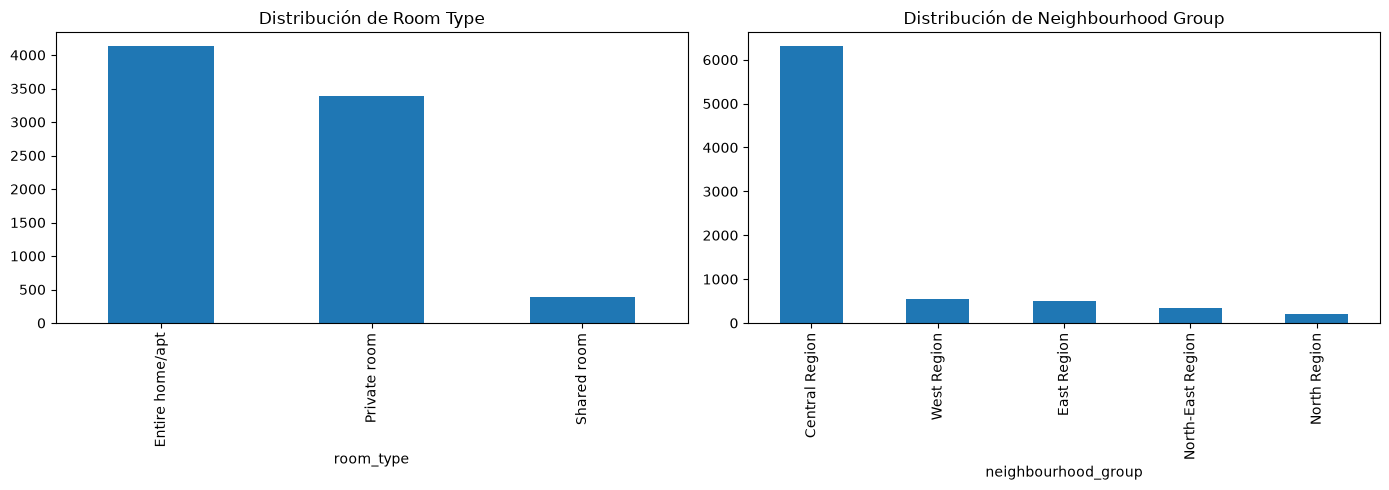

In [15]:
print("Room Type")
print(airbnb['room_type'].value_counts())
print("\nNeighbourhood Group")
print(airbnb['neighbourhood_group'].value_counts())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
airbnb['room_type'].value_counts().plot(kind='bar', ax=axes[0])
axes[0].set_title('Distribución de Room Type')

airbnb['neighbourhood_group'].value_counts().plot(kind='bar', ax=axes[1])
axes[1].set_title('Distribución de Neighbourhood Group')
plt.tight_layout()
plt.show()

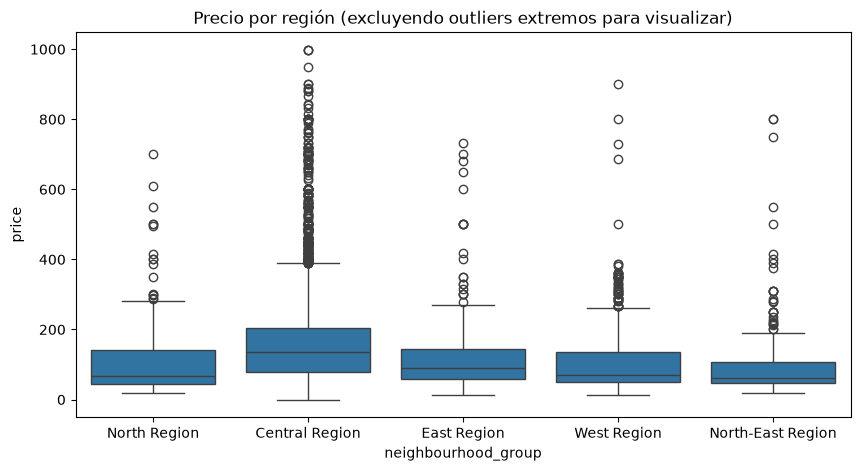

                           mean  median  count
neighbourhood_group                           
Central Region       176.629418   135.0   6309
East Region          142.503937    91.0    508
North Region         110.779412    66.5    204
North-East Region     99.838150    63.0    346
West Region          175.974074    69.0    540


In [16]:
plt.figure(figsize=(10, 5))
sns.boxplot(x='neighbourhood_group', y='price', data=airbnb[airbnb['price'] < 1000])
plt.title('Precio por región (excluyendo outliers extremos para visualizar)')
plt.show()

# Promedio de precio por región (esto es clave para imputación futura)
print(airbnb.groupby('neighbourhood_group')['price'].agg(['mean', 'median', 'count']))

In [17]:
print("Listings con price = 0:", (airbnb['price'] == 0).sum())
print("Listings con minimum_nights > 365:", (airbnb['minimum_nights'] > 365).sum())
print("Listings con availability_365 = 0 pero price alto (>500):", 
      ((airbnb['availability_365'] == 0) & (airbnb['price'] > 500)).sum())

Listings con price = 0: 1
Listings con minimum_nights > 365: 3
Listings con availability_365 = 0 pero price alto (>500): 30


In [18]:
np.random.seed(42)
airbnb_demo2 = airbnb.copy()
mask = np.random.choice(airbnb_demo2.index, size=200, replace=False)
airbnb_demo2.loc[mask, 'price'] = np.nan

print("Faltantes simulados en price:", airbnb_demo2['price'].isnull().sum())

Faltantes simulados en price: 200


In [19]:
mediana_global = airbnb_demo2['price'].median()
imputado_mediana_global = airbnb_demo2['price'].fillna(mediana_global)

mediana_por_region = airbnb_demo2.groupby('neighbourhood_group')['price'].transform('median')
imputado_por_region = airbnb_demo2['price'].fillna(mediana_por_region)

comparacion = pd.DataFrame({
    'neighbourhood_group': airbnb_demo2.loc[mask, 'neighbourhood_group'],
    'mediana_global': imputado_mediana_global.loc[mask],
    'mediana_por_region': imputado_por_region.loc[mask]
})
print(comparacion.head(10))

     neighbourhood_group  mediana_global  mediana_por_region
3641      Central Region           124.0               135.0
5531      Central Region           124.0               135.0
3524         East Region           124.0                90.0
7479      Central Region           124.0               135.0
3455         West Region           124.0                69.0
5751      Central Region           124.0               135.0
3125      Central Region           124.0               135.0
5171      Central Region           124.0               135.0
4055      Central Region           124.0               135.0
2462         East Region           124.0                90.0


In [20]:
print("\nValores únicos usados por 'mediana global':", comparacion['mediana_global'].nunique())
print("Valores únicos usados por 'mediana por región':", comparacion['mediana_por_region'].nunique())
print("\nDetalle de mediana por región:")
print(airbnb_demo2.groupby('neighbourhood_group')['price'].median())


Valores únicos usados por 'mediana global': 1
Valores únicos usados por 'mediana por región': 5

Detalle de mediana por región:
neighbourhood_group
Central Region       135.0
East Region           90.0
North Region          65.0
North-East Region     62.0
West Region           69.0
Name: price, dtype: float64


In [21]:
print("Caso price = 0")
print(airbnb[airbnb['price'] == 0])

print("\nCaso minimum_nights > 365")
print(airbnb[airbnb['minimum_nights'] > 365][['id', 'name', 'neighbourhood_group', 'price', 'minimum_nights']])

Caso price = 0
            id                                   name    host_id host_name  \
3168  21408571  1 BR @ Little India & Farrer Park MRT  114674497     Mitul   

     neighbourhood_group neighbourhood  latitude  longitude        room_type  \
3168      Central Region        Rochor   1.30954  103.85271  Entire home/apt   

      price  minimum_nights  number_of_reviews last_review  reviews_per_month  \
3168      0               3                  9  2019-08-11               0.51   

      calculated_host_listings_count  availability_365  
3168                               6               351  

Caso minimum_nights > 365
            id                                               name  \
1307  11480693                  Luxury Condo Beside The Reservior   
3304  21855881      Where Luxury City Living Reaches New Heights.   
4226  26199521  Very comfortable studio to stay , big balcony ...   

     neighbourhood_group  price  minimum_nights  
1307         East Region    331     

In [22]:
mediana_por_region_real = airbnb.groupby('neighbourhood_group')['price'].transform(
    lambda x: x[x > 0].median()  
)

idx_price_cero = airbnb[airbnb['price'] == 0].index
print("Región del registro con price = 0:", airbnb.loc[idx_price_cero, 'neighbourhood_group'].values)
print("Mediana que se le asignará:", mediana_por_region_real.loc[idx_price_cero].values)

Región del registro con price = 0: <StringArray>
['Central Region']
Length: 1, dtype: str
Mediana que se le asignará: [135.]


In [23]:
airbnb_clean['price'] = airbnb_clean['price'].replace(0, np.nan)
airbnb_clean['price'] = airbnb_clean['price'].fillna(mediana_por_region_real)

print("Quedan precios en 0:", (airbnb_clean['price'] == 0).sum())
print("Quedan precios nulos:", airbnb_clean['price'].isnull().sum())

Quedan precios en 0: 0
Quedan precios nulos: 0


In [24]:
print("Filas antes:", airbnb_clean.shape[0])
airbnb_clean = airbnb_clean[airbnb_clean['minimum_nights'] <= 365]
print("Filas después:", airbnb_clean.shape[0])

Filas antes: 7905
Filas después: 7902


In [25]:
casos_disponibilidad = airbnb_clean[(airbnb_clean['availability_365'] == 0) & (airbnb_clean['price'] > 500)]
print("Cantidad de casos:", len(casos_disponibilidad))
casos_disponibilidad[['id', 'name', 'neighbourhood_group', 'price', 'availability_365', 'number_of_reviews']].head(10)

Cantidad de casos: 29


,id,name,neighbourhood_group,price,availability_365,number_of_reviews
38,804470,Spacious Luxury Condo in Orchard,Central Region,2604.0,0,1
99,1743439,Private room & sofa w/ a TV in a central locat...,Central Region,800.0,0,3
444,5575968,My Room,West Region,1000.0,0,0
456,5655773,Hougang Street 51 private room,North-East Region,800.0,0,0
466,5807596,Small Cozy Masterbed room,Central Region,2000.0,0,0
975,9138262,Designer decor 3bed large apartment,Central Region,750.0,0,0
1119,9958663,Master Bedroom for RENT,Central Region,1350.0,0,0
1183,10343562,City 1 + 1 Bedroom Studio Apartment,Central Region,3500.0,0,0
1408,12055849,Cosy private quiet room near NTU,West Region,800.0,0,0
1484,12613061,YISHUN NEWLY FURNISHED ROOM! HOMEY!,North Region,700.0,0,0


In [26]:
print("Con al menos 1 reseña:", (casos_disponibilidad['number_of_reviews'] > 0).sum())
print("Sin ninguna reseña:", (casos_disponibilidad['number_of_reviews'] == 0).sum())

Con al menos 1 reseña: 4
Sin ninguna reseña: 25


In [27]:
airbnb_clean['posible_listing_inactivo'] = (
    (airbnb_clean['availability_365'] == 0) & 
    (airbnb_clean['price'] > 500) & 
    (airbnb_clean['number_of_reviews'] == 0)
).astype(int)

print("Listings marcados como posiblemente inactivos:", airbnb_clean['posible_listing_inactivo'].sum())


Listings marcados como posiblemente inactivos: 25


In [28]:
print("Filas totalmente duplicadas:", airbnb_clean.duplicated().sum())

print("IDs duplicados:", airbnb_clean['id'].duplicated().sum())
posibles_duplicados = airbnb_clean.duplicated(
    subset=['host_id', 'latitude', 'longitude', 'price'], keep=False
)
print("Posibles duplicados por coincidencia de host+ubicación+precio:", posibles_duplicados.sum())

Filas totalmente duplicadas: 0
IDs duplicados: 0
Posibles duplicados por coincidencia de host+ubicación+precio: 4


In [29]:
inconsistencias = airbnb_clean.groupby('neighbourhood')['neighbourhood_group'].nunique()
inconsistencias = inconsistencias[inconsistencias > 1]
print("Neighbourhoods con más de una región asignada:", len(inconsistencias))
print(inconsistencias)

Neighbourhoods con más de una región asignada: 0
Series([], Name: neighbourhood_group, dtype: int64)


In [30]:
posibles_duplicados = airbnb_clean.duplicated(
    subset=['host_id', 'latitude', 'longitude', 'price'], keep=False
)
airbnb_clean[posibles_duplicados][['id', 'name', 'host_id', 'host_name', 'room_type', 
                                     'latitude', 'longitude', 'price', 'minimum_nights']]

,id,name,host_id,host_name,room_type,latitude,longitude,price,minimum_nights
2641,19164678,Luxury hostel with in-cabin locker - Single mixed,646629,Adler,Shared room,1.28111,103.84427,35.0,1
2650,19164694,Luxury hostel with in-cabin locker - Single mixed,646629,Adler,Shared room,1.28111,103.84427,35.0,1
7901,38104971,2 PAX LOFT Close To Kent Ridge Park,278109833,Belle,Entire home/apt,1.27973,103.78751,100.0,3
7902,38105126,Loft 2 pax near Haw Par / Pasir Panjang. Free ...,278109833,Belle,Entire home/apt,1.27973,103.78751,100.0,3


In [31]:
duplicado_real = airbnb_clean.duplicated(
    subset=['host_id', 'latitude', 'longitude', 'price', 'name'], keep='first'
)
print("Filas antes:", airbnb_clean.shape[0])
airbnb_clean = airbnb_clean[~duplicado_real]
print("Filas después:", airbnb_clean.shape[0])

print(airbnb_clean[airbnb_clean['host_id'].isin([646629, 278109833])]
      [['id', 'name', 'host_id', 'room_type', 'price']])

Filas antes: 7902
Filas después: 7901
            id                                               name    host_id  \
2639  19164675  Luxury hostel with in-cabin locker - Single mixed     646629   
2640  19164677  Luxury hostel with in-cabin locker - Single mixed     646629   
2641  19164678  Luxury hostel with in-cabin locker - Single mixed     646629   
2642  19164680  Luxury hostel with in-cabin locker - Single mixed     646629   
2643  19164681  Luxury hostel with in-cabin locker - Single mixed     646629   
2644  19164682  Luxury hostel with in-cabin locker - Single mixed     646629   
2645  19164684  Luxury hostel with in-cabin locker - Single mixed     646629   
2646  19164687  Luxury hostel with in-cabin locker - Single mixed     646629   
2647  19164690  Luxury hostel with in-cabin locker - Single mixed     646629   
2648  19164691  Luxury hostel with in-cabin locker - Single mixed     646629   
2649  19164693  Luxury hostel with in-cabin locker - Single mixed     646629   
26

In [32]:
print("Estadísticas de price (original):")
print(airbnb_clean['price'].describe())
print("\nSesgo (skewness):", airbnb_clean['price'].skew())

Estadísticas de price (original):
count     7901.000000
mean       169.317428
std        340.256433
min         14.000000
25%         65.000000
50%        124.000000
75%        199.000000
max      10000.000000
Name: price, dtype: float64

Sesgo (skewness): 19.095489861793958


In [33]:
price_min = airbnb_clean['price'].min()
price_max = airbnb_clean['price'].max()
airbnb_clean['price_minmax'] = (airbnb_clean['price'] - price_min) / (price_max - price_min)

In [34]:
price_mean = airbnb_clean['price'].mean()
price_std = airbnb_clean['price'].std()
airbnb_clean['price_zscore'] = (airbnb_clean['price'] - price_mean) / price_std

In [35]:
print("\nMin-Max - min:", airbnb_clean['price_minmax'].min(), 
      "max:", airbnb_clean['price_minmax'].max())
print("Z-score - min:", airbnb_clean['price_zscore'].min(), 
      "max:", airbnb_clean['price_zscore'].max(),
      "media:", airbnb_clean['price_zscore'].mean().round(4))


Min-Max - min: 0.0 max: 1.0
Z-score - min: -0.4564716879745588 max: 28.891981539165013 media: 0.0


In [36]:
print("\n% de listings con price_minmax < 0.05:", 
      (airbnb_clean['price_minmax'] < 0.05).mean() * 100)


% de listings con price_minmax < 0.05: 97.53195798000253


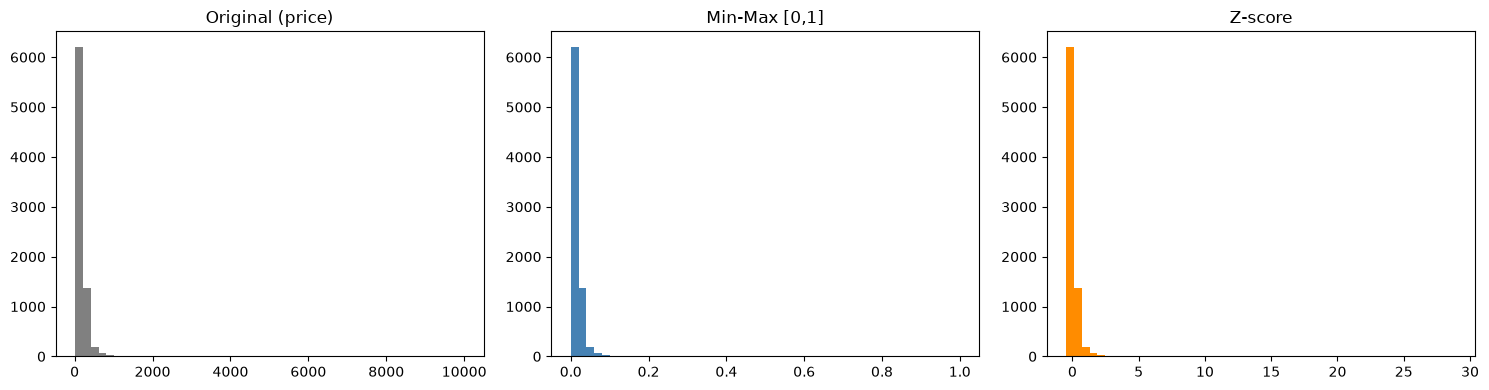

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(airbnb_clean['price'], bins=50, color='gray')
axes[0].set_title('Original (price)')

axes[1].hist(airbnb_clean['price_minmax'], bins=50, color='steelblue')
axes[1].set_title('Min-Max [0,1]')

axes[2].hist(airbnb_clean['price_zscore'], bins=50, color='darkorange')
axes[2].set_title('Z-score')

plt.tight_layout()
plt.show()

In [38]:
variables = ['price', 'minimum_nights', 'number_of_reviews', 
             'reviews_per_month', 'availability_365', 
             'calculated_host_listings_count']

corr_matrix = airbnb_clean[variables].corr(method='pearson')

corr_con_price = corr_matrix['price'].drop('price').sort_values(key=abs, ascending=False)

print("Correlación de pearson de cada predictor con 'price':")
print(corr_con_price)

Correlación de pearson de cada predictor con 'price':
number_of_reviews                -0.041988
reviews_per_month                -0.030767
availability_365                  0.017912
calculated_host_listings_count    0.016603
minimum_nights                   -0.012517
Name: price, dtype: float64


In [39]:
variables = ['price', 'minimum_nights', 'number_of_reviews', 
             'reviews_per_month', 'availability_365', 
             'calculated_host_listings_count']

corr_matrix = airbnb_clean[variables].corr(method='spearman')

corr_con_price = corr_matrix['price'].drop('price').sort_values(key=abs, ascending=False)

print("Correlación de spearman de cada predictor con 'price':")
print(corr_con_price)

Correlación de spearman de cada predictor con 'price':
calculated_host_listings_count    0.258409
availability_365                  0.099113
number_of_reviews                -0.081774
reviews_per_month                -0.038623
minimum_nights                    0.023991
Name: price, dtype: float64


In [40]:
predictores = ['minimum_nights', 'number_of_reviews', 
               'reviews_per_month', 'availability_365', 
               'calculated_host_listings_count']

corr_pearson = airbnb_clean[predictores].corr(method='pearson')

print("Colinealidad - Pearson")
print(corr_pearson.round(3))

print("\nPares con posible colinealidad")
for i in range(len(predictores)):
    for j in range(i+1, len(predictores)):
        rp = corr_pearson.iloc[i, j]
        if abs(rp) > 0.5:
            print(f"{predictores[i]} <-> {predictores[j]}: Pearson={rp:.3f}")

Colinealidad - Pearson
                                minimum_nights  number_of_reviews  \
minimum_nights                           1.000             -0.079   
number_of_reviews                       -0.079              1.000   
reviews_per_month                       -0.155              0.674   
availability_365                         0.157             -0.067   
calculated_host_listings_count          -0.011             -0.150   

                                reviews_per_month  availability_365  \
minimum_nights                             -0.155             0.157   
number_of_reviews                           0.674            -0.067   
reviews_per_month                           1.000            -0.108   
availability_365                           -0.108             1.000   
calculated_host_listings_count             -0.181             0.246   

                                calculated_host_listings_count  
minimum_nights                                          -0.011  
numbe

In [41]:
predictores = ['minimum_nights', 'number_of_reviews', 
               'reviews_per_month', 'availability_365', 
               'calculated_host_listings_count']

corr_spearman = airbnb_clean[predictores].corr(method='spearman')

print("\nColinealidad - Spearman")
print(corr_spearman.round(3))

print("\nPares con posible colinealidad")
for i in range(len(predictores)):
    for j in range(i+1, len(predictores)):
        rs = corr_spearman.iloc[i, j]
        if abs(rs) > 0.5:
            print(f"{predictores[i]} <-> {predictores[j]}: Spearman={rs:.3f}")


Colinealidad - Spearman
                                minimum_nights  number_of_reviews  \
minimum_nights                           1.000             -0.222   
number_of_reviews                       -0.222              1.000   
reviews_per_month                       -0.248              0.906   
availability_365                         0.206             -0.133   
calculated_host_listings_count           0.243             -0.093   

                                reviews_per_month  availability_365  \
minimum_nights                             -0.248             0.206   
number_of_reviews                           0.906            -0.133   
reviews_per_month                           1.000            -0.126   
availability_365                           -0.126             1.000   
calculated_host_listings_count             -0.056             0.412   

                                calculated_host_listings_count  
minimum_nights                                           0.243  
num

In [42]:
predictores = ['minimum_nights', 'number_of_reviews', 
               'reviews_per_month', 'availability_365', 
               'calculated_host_listings_count']

X = airbnb_clean[predictores].dropna()

vif_data = pd.DataFrame()
vif_data['variable'] = predictores
vif_data['VIF'] = [variance_inflation_factor(X.values, i) for i in range(len(predictores))]

print(vif_data.sort_values('VIF', ascending=False))

                         variable       VIF
2               reviews_per_month  2.310903
1               number_of_reviews  2.176704
3                availability_365  1.902607
4  calculated_host_listings_count  1.455340
0                  minimum_nights  1.213143
